## Description
This notebook generates visualizations and outputs them to results/visualisations to better understand how the model results come about. It is structured like:
1. Imports
2. Setting technology colors for some visualisations
3. All functions
4. Loading model runs
5. Inspecting results and using of functions for visualisations

# 1

### Imports

In [37]:
from pathlib import Path
import re
import warnings
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
import numpy as np
import pandas as pd
import pypsa
from IPython.display import display

years = [2020, 2030, 2040, 2050]

# 2

### Setting technology colors for visualization

In [38]:
tech_colors = {
    # Electricity generation
    "CCGT": "#D98242",
    "CCGT CCS": "#A65E2E",
    "Biomass plant": "#71A45B",
    "Biomass plant CCS": "#3F743D",
    "Nuclear plant": "#9670BA",
    "Solar PV": "#E8BC38",
    "Wind turbine - onshore": "#55B5B0",
    "Wind turbine - offshore": "#278580",

    # Transport
    "BEV": "#5188C3",
    "ICE car": "#BC885F",

    # Residential demand and heating
    "Residential Appliance": "#B0B5BC",
    "Residential gas boiler": "#C98B51",
    "Residential heat pump": "#79A9D3",

    # Electricity storage
    "Battery": "#415F9D",

    # Industrial machinery
    "Industrial machinery - fossil": "#B77A4B",
    "Industrial machinery - fossil CCS": "#885735",
    "Industrial machinery - electricity": "#3976B5",

    # Industrial high-temperature processes
    "Industrial HTP - fossil": "#A66B43",
    "Industrial HTP - fossil CCS": "#754A30",

    # Hydrogen production
    "SMR": "#C17B42",
    "SMR with CCS": "#92592F",
    "Electrolysis": "#609BCD",

    # Existing assets: matching hue, reduced opacity (~60%)
    "BEV - existing": "#5188C399",
    "ICE car - existing": "#BC885F99",
    "CCGT - existing": "#D9824299",
    "Residential gas boiler - existing": "#C98B5199",
    "Industrial machinery - fossil - existing": "#B77A4B99",
    "Industrial HTP - fossil - existing": "#A66B4399",
    "SMR - existing": "#C17B4299",
    "SMR with CCS - existing": "#92592F99",
    "Electrolysis - existing": "#609BCD99",
}

# 3

### Handy plotting functions from the final course notebook

In [39]:
# Handy plotting functions. 
# Note that these are good to quickly diagnose your runs, 
# but for your final presentation and paper you will need
# nicer-looking plots, following the data-visualization 
# guidelines we discussed in class!

def plot_main_ebs(scen):
    fig, ax = plt.subplots(1, 1)
    fig.set_size_inches(10, 4)

    df = scen.statistics.energy_balance(bus_carrier='Hydrogen')
    df = df.set_index(df.index.get_level_values(1)).T
    df.plot(kind='bar', stacked='True', rot=0, colormap="tab20", ax=ax)
    ax.set_ylabel('MWh')
    ax.set_title(scen.name)

    fig.tight_layout()

def plot_main_ebs_complete(scen):
    fig, ax = plt.subplots(1,5)
    fig.set_size_inches(20,4)

    for n,c in enumerate(['Residential electricity',
            'Residential heat',
            'Transportation',
            'Industrial machinery',
            'Industrial HTP']): 
        df = scen.statistics.energy_balance(bus_carrier=c)
        df = df.set_index(df.index.get_level_values(1)).T
        df.plot(kind='bar',stacked='True', rot=0, colormap="tab20",ax=ax[n])
        if c=='Transportation':
            ax[n].set_ylabel('Mvkm')
        else:
            ax[n].set_ylabel('MWh')
        ax[n].set_title(c)

    fig.tight_layout()

def plot_elc_emi(scen):
    fig, ax = plt.subplots(1,5)
    fig.set_size_inches(20,4)

    for n,c in enumerate(['Electricity','CO2 atmosphere', 'CO2 storage']):
        df = scen.statistics.energy_balance(bus_carrier=c)
        df = df.set_index(df.index.get_level_values(1)).T
        df.plot(kind='bar',stacked='True', rot=0, colormap="tab20", ax=ax[n])

        if 'CO2' in c:
            ax[n].set_ylabel('tCO2')
        else:
            ax[n].set_ylabel('MWh')
        ax[n].set_title(c)
        ax[n].legend(bbox_to_anchor=(1,-0.5))

    # Let's add cumulative CO2
    for n,c in enumerate(['CO2 atmosphere', 'CO2 storage']):
        df = scen.statistics.energy_balance(bus_carrier=c).cumsum(axis=1)
        df = df.set_index(df.index.get_level_values(1))
        df.T.plot(kind='bar', stacked=True, colormap='tab20', ax=ax[n+3])
        ax[n+3].set_ylabel('tCO2')
        ax[n+3].set_title(f'Cumulative {c}')
        ax[n+3].legend(bbox_to_anchor=(1,-0.5))

    fig.tight_layout()


INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'default_tech_low_carbon' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks
INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'default_tech_high_carbon' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks
INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'improved_tech_low_carbon' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks
INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.0)
INFO:pypsa.network.io:Imported network 'improved_tech_high_carbon' has buses, carriers, generators, links, loads, storage_units, stores, sub_networks


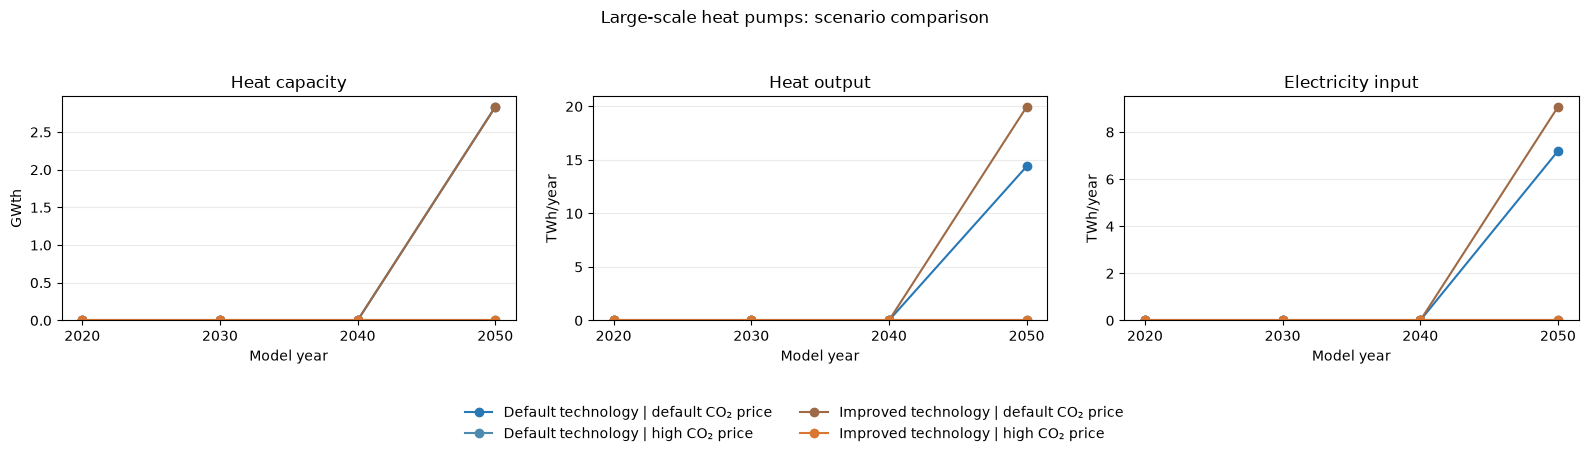

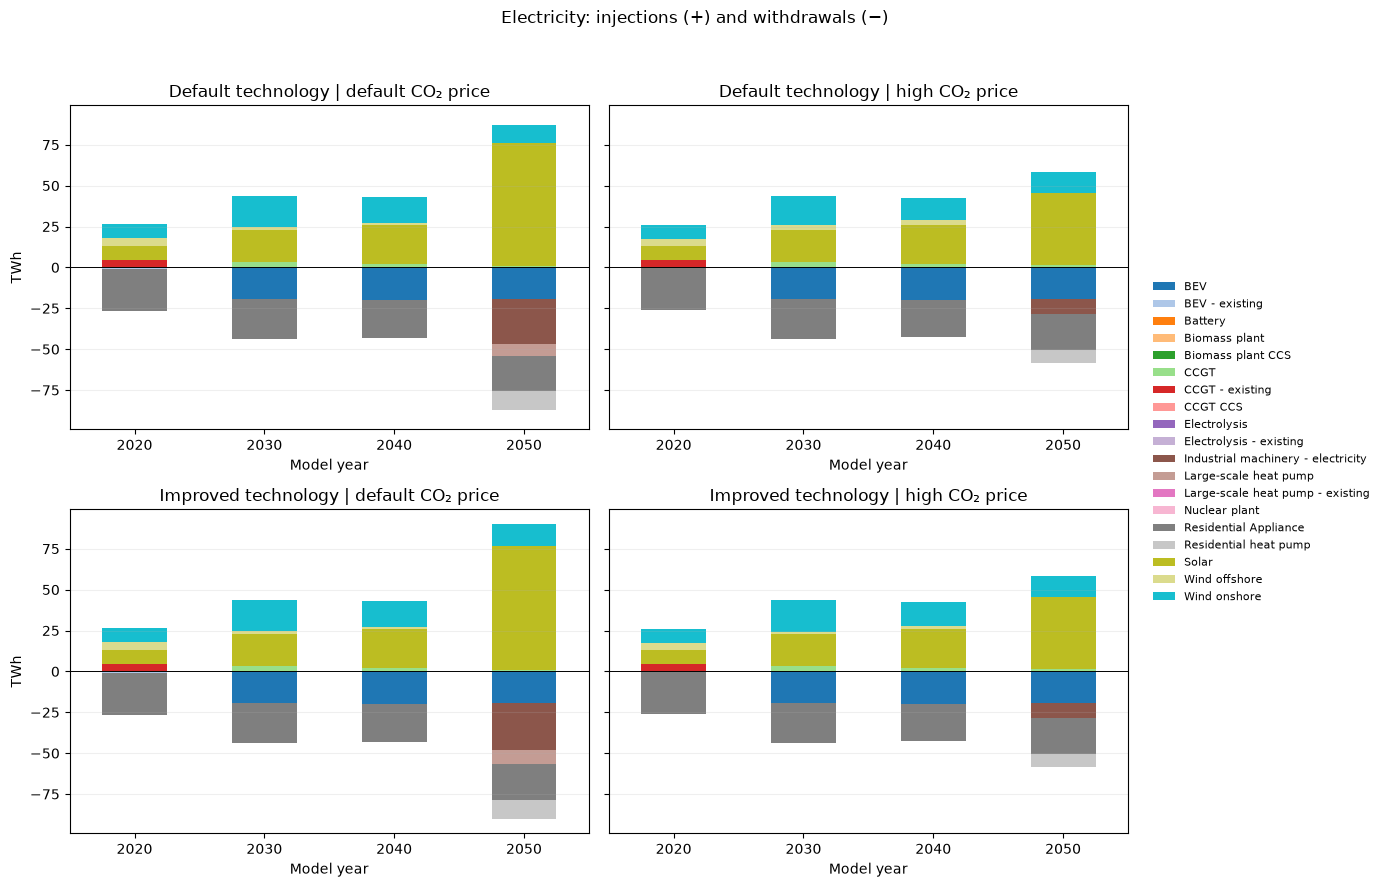

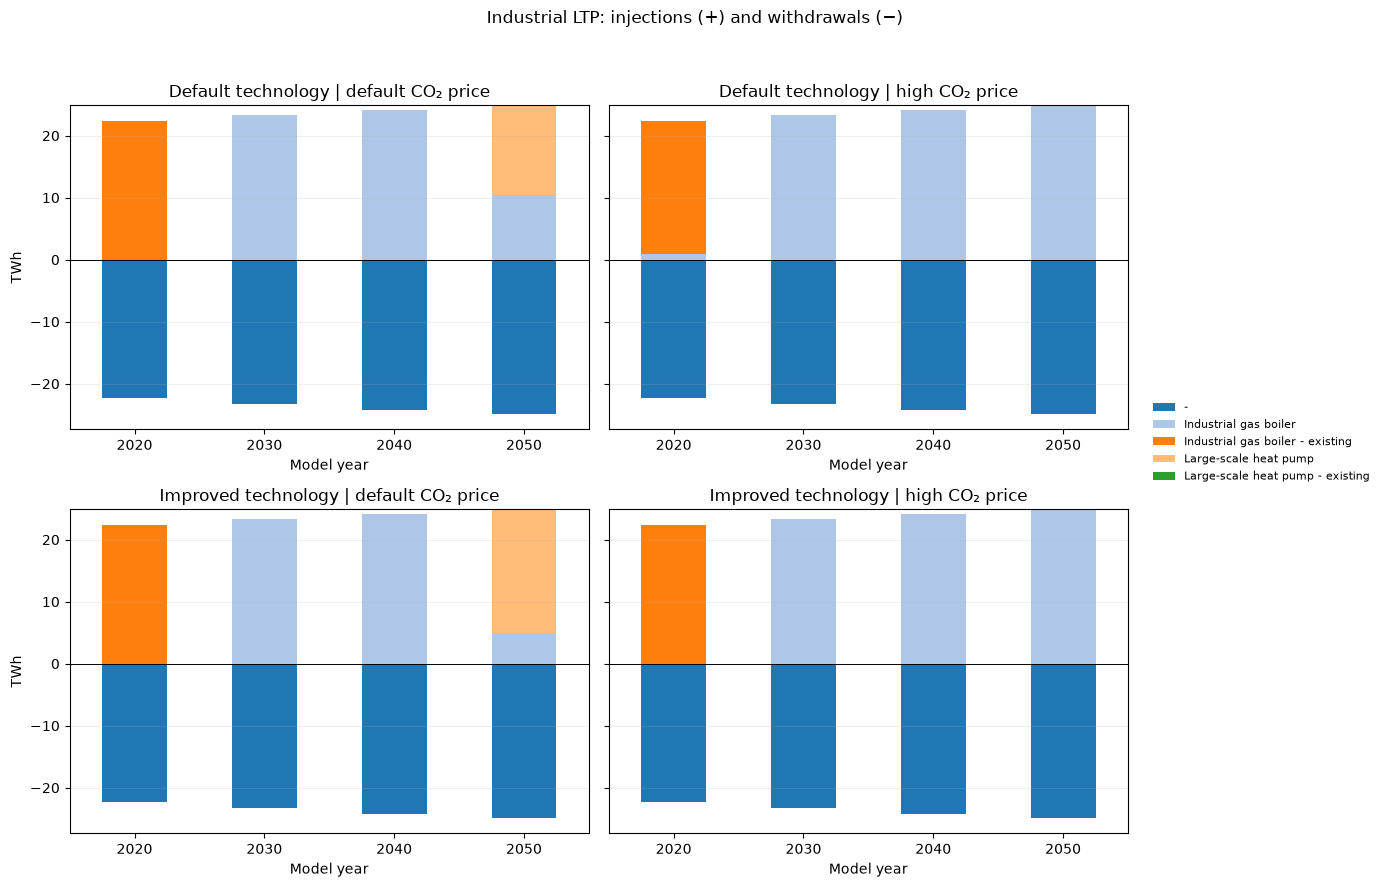

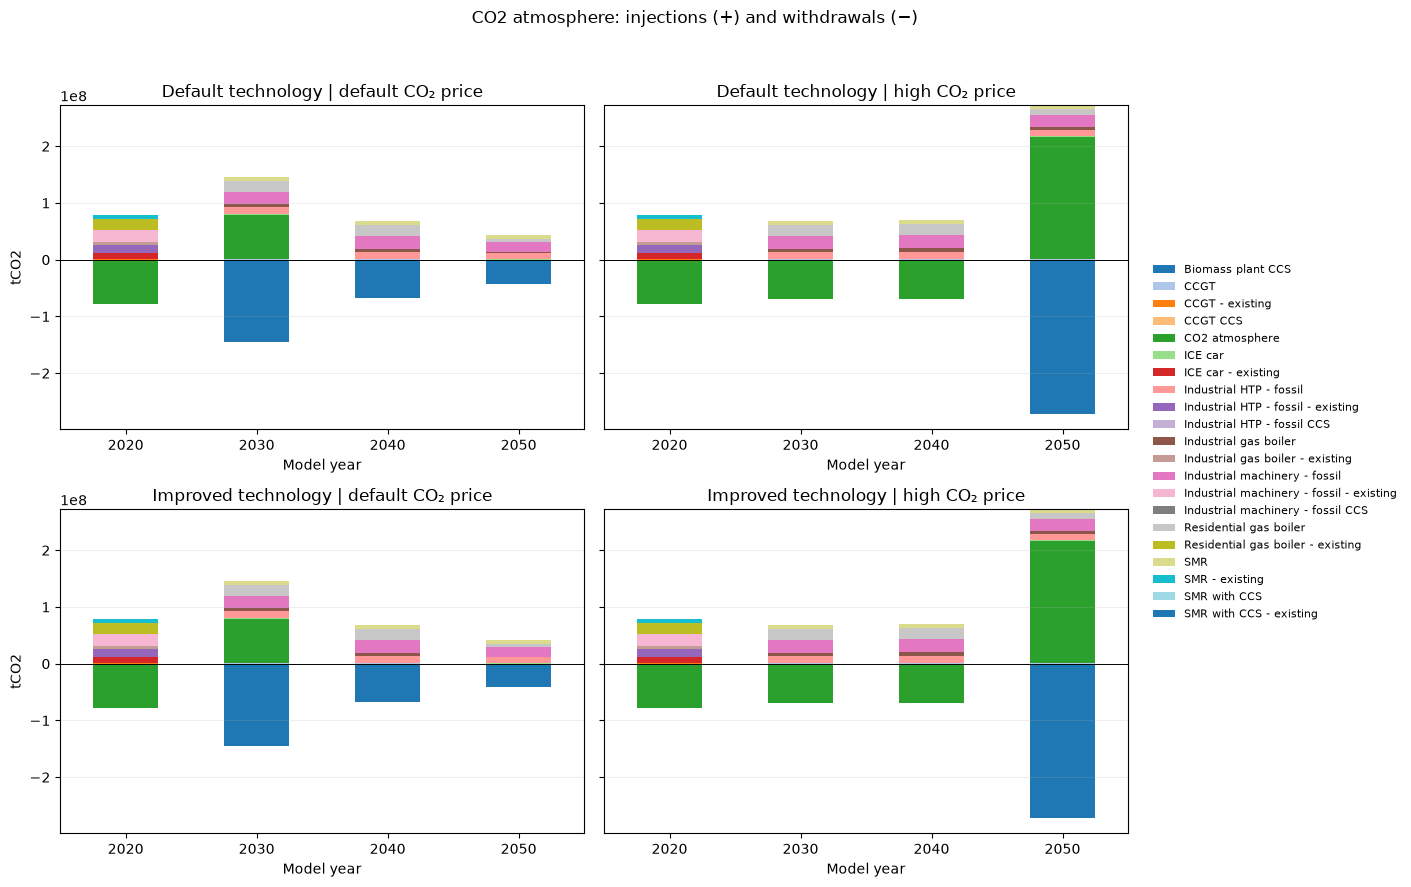

In [40]:
RESULTS_DIR = Path("results/temporal_scenarios")
SCENARIOS = ["default_tech_low_carbon", "default_tech_high_carbon", "improved_tech_low_carbon", "improved_tech_high_carbon"]
LABELS = {
    "default_tech_low_carbon": "Default technology | default CO₂ price",
    "default_tech_high_carbon": "Default technology | high CO₂ price",
    "improved_tech_low_carbon": "Improved technology | default CO₂ price",
    "improved_tech_high_carbon": "Improved technology | high CO₂ price",
}
COLORS = {
    "default_tech_low_carbon": "#2878B5",
    "default_tech_high_carbon": "#4C8AAE",
    "improved_tech_low_carbon": "#9E6A45",
    "improved_tech_high_carbon": "#D97732",
}

networks = {}
for scenario in SCENARIOS:
    file = RESULTS_DIR / f"{scenario}.nc"
    if not file.exists():
        raise FileNotFoundError(f"Missing scenario result: {file}")
    networks[scenario] = pypsa.Network(str(file))


def heatpump_metrics(n):
    """Active output capacity, annual heat, and annual electricity input.

    Assumes the heat pump is a Link with electricity at bus0 and useful
    heat at bus1, as in the model's two-bus Link implementation.
    Includes active older investment vintages, not just new builds.
    """
    if not isinstance(n.snapshots, pd.MultiIndex):
        raise ValueError("Expected multi-period snapshots (period, timestamp).")

    hp = n.links.index[n.links["carrier"].eq("Large-scale heat pump")]
    if len(hp) == 0:
        raise ValueError(f"No large-scale heat-pump Links found in {n.name}.")

    missing = hp.difference(n.links_t.p0.columns).union(
        hp.difference(n.links_t.p1.columns)
    )
    if len(missing):
        raise ValueError(f"Missing optimized heat-pump dispatch: {list(missing)}")

    periods = list(n.investment_periods)
    result = pd.DataFrame(
        index=pd.Index(periods, name="Model year"),
        columns=["Heat capacity (GWth)", "Heat output (TWh/year)",
                 "Electricity input (TWh/year)"],
        dtype=float,
    )

    for year in periods:
        # Link p_nom is input capacity. Multiply by COP/efficiency to obtain
        # heat-output capacity. Do not sum expired or future vintages.
        active_mask = (
            n.links.loc[hp, "build_year"].le(year)
            & (n.links.loc[hp, "build_year"] + n.links.loc[hp, "lifetime"]).gt(year)
        )
        active = hp[active_mask.to_numpy()]
        result.loc[year, "Heat capacity (GWth)"] = (
            n.links.loc[active, "p_nom_opt"]
            * n.links.loc[active, "efficiency"]
        ).sum() / 1e3

        snapshots = n.snapshots[n.snapshots.get_level_values(0) == year]
        # These weights account for the hours represented by each snapshot.
        # Do not multiply by the decade's investment-period weighting here:
        # the result is annual energy, not total energy over the whole decade.
        weights = n.snapshot_weightings.loc[snapshots, "generators"]
        heat = -n.links_t.p1.loc[snapshots, hp].sum(axis=1)
        electricity = n.links_t.p0.loc[snapshots, hp].sum(axis=1)
        result.loc[year, "Heat output (TWh/year)"] = heat.mul(weights).sum() / 1e6
        result.loc[year, "Electricity input (TWh/year)"] = (
            electricity.mul(weights).sum() / 1e6
        )

    return result


metrics = {scenario: heatpump_metrics(n) for scenario, n in networks.items()}

# FIGURE 1: Direct comparison of the heat-pump results.
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, metric in zip(axes, next(iter(metrics.values())).columns):
    for scenario in SCENARIOS:
        ax.plot(
            metrics[scenario].index,
            metrics[scenario][metric],
            label=LABELS[scenario],
            color=COLORS[scenario],
            linestyle="--" if scenario.endswith("high") else "-",
            marker="o",
        )
    ax.set_title(metric.split(" (")[0])
    ax.set_ylabel(metric.split("(")[1].rstrip(")"))
    ax.set_xlabel("Model year")
    ax.set_xticks(next(iter(metrics.values())).index)
    ax.grid(axis="y", alpha=0.25)
    ax.set_ylim(bottom=0)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False)
fig.suptitle("Large-scale heat pumps: scenario comparison")
fig.tight_layout(rect=[0, 0.16, 1, 0.94])
plt.show()


def plot_energy_balance_comparison(bus_carrier="Electricity", unit="TWh"):
    """Four stacked energy balances, adapted from the supplied functions.

    Positive bars are injections into the selected bus carrier;
    negative bars are withdrawals. Values use PyPSA's statistics aggregation.
    Suitable for energy carriers; use unit='tCO2' for emissions carriers.
    """
    if unit not in {"TWh", "MWh", "tCO2"}:
        raise ValueError("Choose TWh, MWh, or tCO2.")
    scale = 1e6 if unit == "TWh" else 1.0
    balances = {}
    for scenario, n in networks.items():
        df = n.statistics.energy_balance(bus_carrier=bus_carrier)
        if not isinstance(df, pd.DataFrame):
            raise ValueError("Expected statistics columns to represent model years.")
        if not set(n.investment_periods).issubset(df.columns):
            raise ValueError(f"Unexpected statistics columns: {list(df.columns)}")
        if df.empty:
            raise ValueError(f"No energy balance found for {bus_carrier!r}.")
        # Aggregate duplicate carriers rather than simply relabelling rows.
        if isinstance(df.index, pd.MultiIndex):
            level = "carrier" if "carrier" in df.index.names else 1
            df = df.groupby(level=level).sum()
        else:
            df = df.groupby(level=0).sum()
        balances[scenario] = df.loc[:, list(n.investment_periods)].T / scale

    carriers = sorted(set().union(*(set(df.columns) for df in balances.values())))
    colors = {c: plt.get_cmap("tab20")(i % 20) for i, c in enumerate(carriers)}
    fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharey=True)
    for ax, scenario in zip(axes.flat, SCENARIOS):
        df = balances[scenario].reindex(columns=carriers, fill_value=0).fillna(0)
        df.plot.bar(
            stacked=True, rot=0, ax=ax,
            color=[colors[c] for c in carriers], legend=False,
        )
        ax.axhline(0, color="black", linewidth=0.7)
        ax.set_title(LABELS[scenario])
        ax.set_ylabel(unit)
        ax.set_xlabel("Model year")
        ax.grid(axis="y", alpha=0.2)
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="center left", bbox_to_anchor=(0.82, 0.5),
               frameon=False, fontsize=8)
    fig.suptitle(f"{bus_carrier}: injections (+) and withdrawals (−)")
    fig.tight_layout(rect=[0, 0, 0.82, 0.95])
    plt.show()


# FIGURE 2: Electricity balances for all four scenarios.
plot_energy_balance_comparison("Electricity", unit="TWh")

# Optional: uncomment ONE of these to inspect another balance.
# Use exact bus-carrier names from your input database.
# plot_energy_balance_comparison("Residential heat", unit="TWh")
plot_energy_balance_comparison("Industrial LTP", unit="TWh")
# plot_energy_balance_comparison("Hydrogen", unit="TWh")
plot_energy_balance_comparison("CO2 atmosphere", unit="tCO2")

# 4

### Load saved models

# 5

### Turn the already solved networks into results tables